# Room sweeps — phase variance

Same loading as `roomsweeps_processing.ipynb` up to θ̂/α̂, then a linear fit of θ̂ over frequency per link.

Data: `roomsweeps_data/<exp>/` (CSV + `positions.txt`).
Floor labels 1–136 are located in 3-D in the merged room scan `roomscans/merged.ply`;
their centres are in `roomscans/merged_markers.csv` (metres, z up, floor ≈ 0).

In [33]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import open3d as o3d

ROOT = Path.cwd()
DATA_DIR = ROOT / "roomsweeps_data"
SCAN_DIR = ROOT / "roomscans"
MESH_PATH = SCAN_DIR / "merged.ply"
MARKERS_PATH = SCAN_DIR / "merged_markers.csv"

# one colour per tag column (tags 1-5, 6-10, 15-19)
TAG_GROUPS = {"T1–T5": range(1, 6), "T6–T10": range(6, 11), "T15–T19": range(15, 20)}
GROUP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

## Floor markers (label → x, y, z in the merged scan)

In [ ]:
markers = pd.read_csv(MARKERS_PATH).set_index("index").sort_index()
print(f"{len(markers)} markers, labels {markers.index.min()}–{markers.index.max()}")
print(markers.groupby("scene").size().rename("markers per scan").to_string())


def marker_xyz(label):
    """Floor label -> (x, y, z) in metres. `under-N` is one step past N along N's column."""
    label = str(label).strip()
    m = re.fullmatch(r"under-(\d+)", label)
    if m:
        n = int(m.group(1))
        p, prev = markers.loc[n, ["x", "y", "z"]], markers.loc[n - 1, ["x", "y", "z"]]
        return tuple(p + (p - prev))
    return tuple(markers.loc[int(label), ["x", "y", "z"]])

136 markers, labels 1–136
scene
mapping_2214_1_marked    30
mapping_2214_2_marked    30
mapping_2214_3_marked    30
mapping_2214_4_marked    30
mapping_2214_5_marked    16


: 

: 

: 

## Experiments and tag positions

In [ ]:
INFER_MISSING = True   # fill experiments without positions.txt from the leapfrog pattern below


def positions_frame(tags, labels, source):
    df = pd.DataFrame({"tag": [str(t).strip() for t in tags], "label": [str(l).strip() for l in labels]})
    df[["x", "y", "z"]] = np.array([marker_xyz(l) for l in df["label"]])
    df["source"] = source
    return df.set_index("tag")


def load_positions(exp_dir):
    """positions.txt -> DataFrame indexed by tag number with label, x, y, z (None if file missing)."""
    path = exp_dir / "positions.txt"
    if not path.exists():
        return None
    df = pd.read_csv(path, skipinitialspace=True, dtype=str).dropna()
    return positions_frame(df.iloc[:, 0], df.iloc[:, 1], "file")


def infer_positions(exp_num):
    """Leapfrog sweep seen in every positions.txt: exp n occupies grid columns n-1, n, n+1 (rows 1-5),
    and each step the last tag column jumps to the front, so the group order rotates by one."""
    groups = [list(g) for g in TAG_GROUPS.values()]
    k = (exp_num - 1) % 3
    groups = groups[k:] + groups[:k]
    tags, labels = [], []
    for i, group in enumerate(groups):
        col = exp_num - 1 + i
        tags += group
        labels += [col * 8 + row for row in range(1, 6)]
    return positions_frame(tags, labels, "inferred")


exp_dirs = sorted((d for d in DATA_DIR.iterdir() if d.is_dir()), key=lambda d: int(d.name))
positions = {d.name: load_positions(d) for d in exp_dirs}

# the pattern must reproduce every positions.txt we do have
for name, pos in positions.items():
    if pos is not None:
        guess = infer_positions(int(name))["label"]
        assert (guess.loc[pos.index] == pos["label"]).all(), f"leapfrog pattern doesn't match exp {name}"

inventory = pd.DataFrame({
    "positions.txt": [positions[d.name] is not None for d in exp_dirs],
    "csv": [len(list(d.glob("*.csv"))) for d in exp_dirs],
    "pdfs": [len(list(d.glob("*.pdf"))) for d in exp_dirs],
}, index=[d.name for d in exp_dirs]).rename_axis("exp")
print(inventory.to_string())

if INFER_MISSING:
    positions = {name: pos if pos is not None else infer_positions(int(name)) for name, pos in positions.items()}
for name, pos in positions.items():
    if pos is not None:
        print(f"exp {name} ({pos['source'].iloc[0]}): " + ", ".join(f"T{t}@{l}" for t, l in pos["label"].items()))

     positions.txt  csv  pdfs
exp                          
1             True    1     3
2             True    1     3
3             True    1     3
4             True    1     3
5             True    1     3
6             True    1     3
7             True    1     3
8             True    1     3
9             True    1     3
10            True    1     3
11            True    1     3
12            True    1     3
13            True    1     3
14            True    1     3
15            True    1     3
exp 1 (file): T1@1, T2@2, T3@3, T4@4, T5@5, T6@9, T7@10, T8@11, T9@12, T10@13, T15@17, T16@18, T17@19, T18@20, T19@21
exp 2 (file): T6@9, T7@10, T8@11, T9@12, T10@13, T15@17, T16@18, T17@19, T18@20, T19@21, T1@25, T2@26, T3@27, T4@28, T5@29
exp 3 (file): T15@17, T16@18, T17@19, T18@20, T19@21, T1@25, T2@26, T3@27, T4@28, T5@29, T6@33, T7@34, T8@35, T9@36, T10@37
exp 4 (file): T1@25, T2@26, T3@27, T4@28, T5@29, T6@33, T7@34, T8@35, T9@36, T10@37, T15@41, T16@42, T17@43, T18@44, T19@45
e

: 

: 

: 

## Room background (top-down view of the merged scan)

In [ ]:
mesh = o3d.io.read_triangle_mesh(str(MESH_PATH))
verts = np.asarray(mesh.vertices)


FLOOR_Z = 0.15            # below: floor, drawn light grey (the marker spheres in the scan are coloured, so not its own colour)
OBST_Z = (0.3, 2.0)       # between: walls/furniture, drawn as dark silhouettes
rng = np.random.default_rng(0)

floor = verts[:, 2] < FLOOR_Z
obst = (verts[:, 2] > OBST_Z[0]) & (verts[:, 2] < OBST_Z[1])
floor_idx = rng.choice(np.flatnonzero(floor), min(80_000, floor.sum()), replace=False)
obst_idx = rng.choice(np.flatnonzero(obst), min(40_000, obst.sum()), replace=False)


def draw_room(ax):
    ax.scatter(verts[floor_idx, 0], verts[floor_idx, 1], c="#cfcfcf", s=0.3, alpha=0.5,
               linewidths=0, rasterized=True)
    ax.scatter(verts[obst_idx, 0], verts[obst_idx, 1], c="#555555", s=0.3, alpha=0.35,
               linewidths=0, rasterized=True)
    ax.scatter(markers["x"], markers["y"], s=6, c="#9a9a9a", zorder=2)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")

: 

: 

: 

## Region convention (see `roomsweeps_convention.md`)

- **Direction 0** = across columns (1 → 9 → … → 129): **Edge02** (cols 0–2, labels 1–24), **Center0** (cols 3–13, 25–112), **Edge01** (cols 14–16, 113–136).
- **Direction 1** = down a column (1 → 8): **Edge10** (rows 1–4), **Center1** (rows 5–8).

`label_regions(n)` → `(direction-0 region, direction-1 region)`, e.g. `label_regions(50)` → `('Center0', 'Edge10')`.

In [ ]:
DIR0_REGIONS = {"Edge02": range(0, 3), "Center0": range(3, 14), "Edge01": range(14, 17)}   # grid columns
DIR1_REGIONS = {"Edge10": range(0, 4), "Center1": range(4, 8)}                            # grid rows (0 = label 1's row)
REGION_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]


def label_regions(n):
    """Floor label -> (direction-0 region, direction-1 region)."""
    col, row = (int(n) - 1) // 8, (int(n) - 1) % 8
    r0 = next(name for name, cols in DIR0_REGIONS.items() if col in cols)
    r1 = next(name for name, rows in DIR1_REGIONS.items() if row in rows)
    return r0, r1


markers[["dir0_region", "dir1_region"]] = [label_regions(n) for n in markers.index]


def grid_xy(col, row):
    """(x, y) of the marker at grid (col, row)."""
    return markers.loc[col * 8 + row + 1, ["x", "y"]].to_numpy(float)


def draw_regions(ax, color="#555555"):
    """Dashed boundaries between regions and region names outside the grid (as on the whiteboard sketch)."""
    for c in [max(r) for r in list(DIR0_REGIONS.values())[:-1]]:             # between col c and c+1
        pts = np.array([(grid_xy(c, r) + grid_xy(c + 1, r)) / 2 for r in range(8)])
        ax.plot(pts[:, 0], pts[:, 1], ls="--", lw=1.2, color=color, zorder=2)
    for r in [max(rr) for rr in list(DIR1_REGIONS.values())[:-1]]:          # between row r and r+1
        pts = np.array([(grid_xy(c, r) + grid_xy(c, r + 1)) / 2 for c in range(17)])
        ax.plot(pts[:, 0], pts[:, 1], ls="--", lw=1.2, color=color, zorder=2)
    for name, cols in DIR0_REGIONS.items():                                   # below the last row
        p = np.mean([grid_xy(c, 7) for c in cols], axis=0)
        step = grid_xy(cols[0], 7) - grid_xy(cols[0], 6)
        ax.annotate(name, p + 2.2 * step, ha="center", va="center", fontsize=11, fontweight="bold", color=color)
    for name, rows in DIR1_REGIONS.items():                                   # past the last column
        p = np.mean([grid_xy(16, r) for r in rows], axis=0)
        step = grid_xy(16, rows[0]) - grid_xy(15, rows[0])
        ax.annotate(name, p + 2.2 * step, ha="center", va="center", fontsize=11, fontweight="bold", color=color)

: 

: 

: 

## Floor labels in the room

All 136 floor labels from `merged_markers.csv` on the top-down room scan, no tags. Dashed lines and names mark the regions (see the region convention below and `roomsweeps_convention.md`).

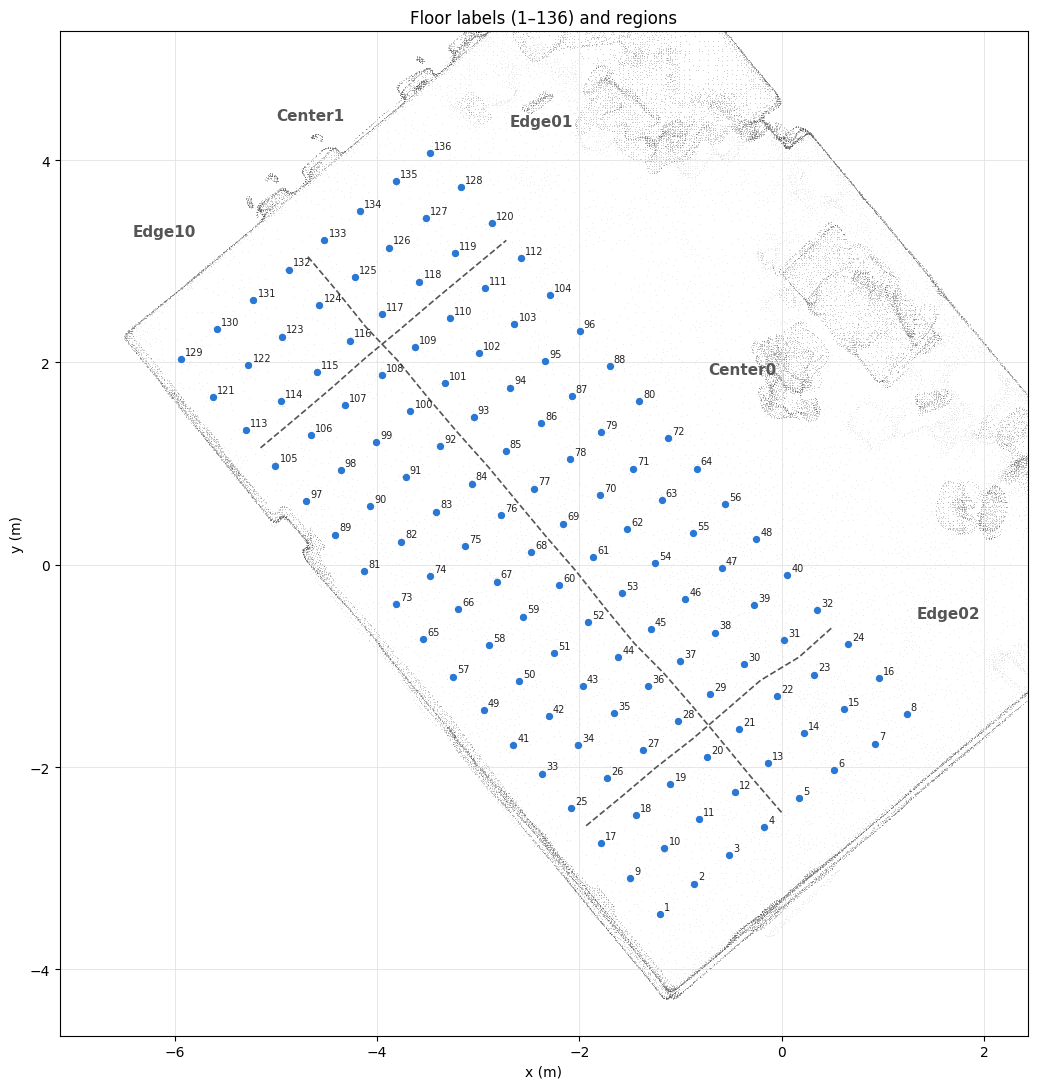

: 

: 

: 

In [ ]:
fig, ax = plt.subplots(figsize=(11, 11))
draw_room(ax)
ax.scatter(markers["x"], markers["y"], s=18, c="#2a78d6", zorder=3)
for lab, r in markers.iterrows():
    ax.annotate(str(lab), (r.x, r.y), xytext=(3, 3), textcoords="offset points",
                fontsize=7, color="#222222", zorder=4)
draw_regions(ax)
pad = 1.2
ax.set_xlim(markers["x"].min() - pad, markers["x"].max() + pad)
ax.set_ylim(markers["y"].min() - pad, markers["y"].max() + pad)
ax.grid(True, color="#dddddd", lw=0.5)
ax.set_title("Floor labels (1–136) and regions")
fig.tight_layout()
plt.show()

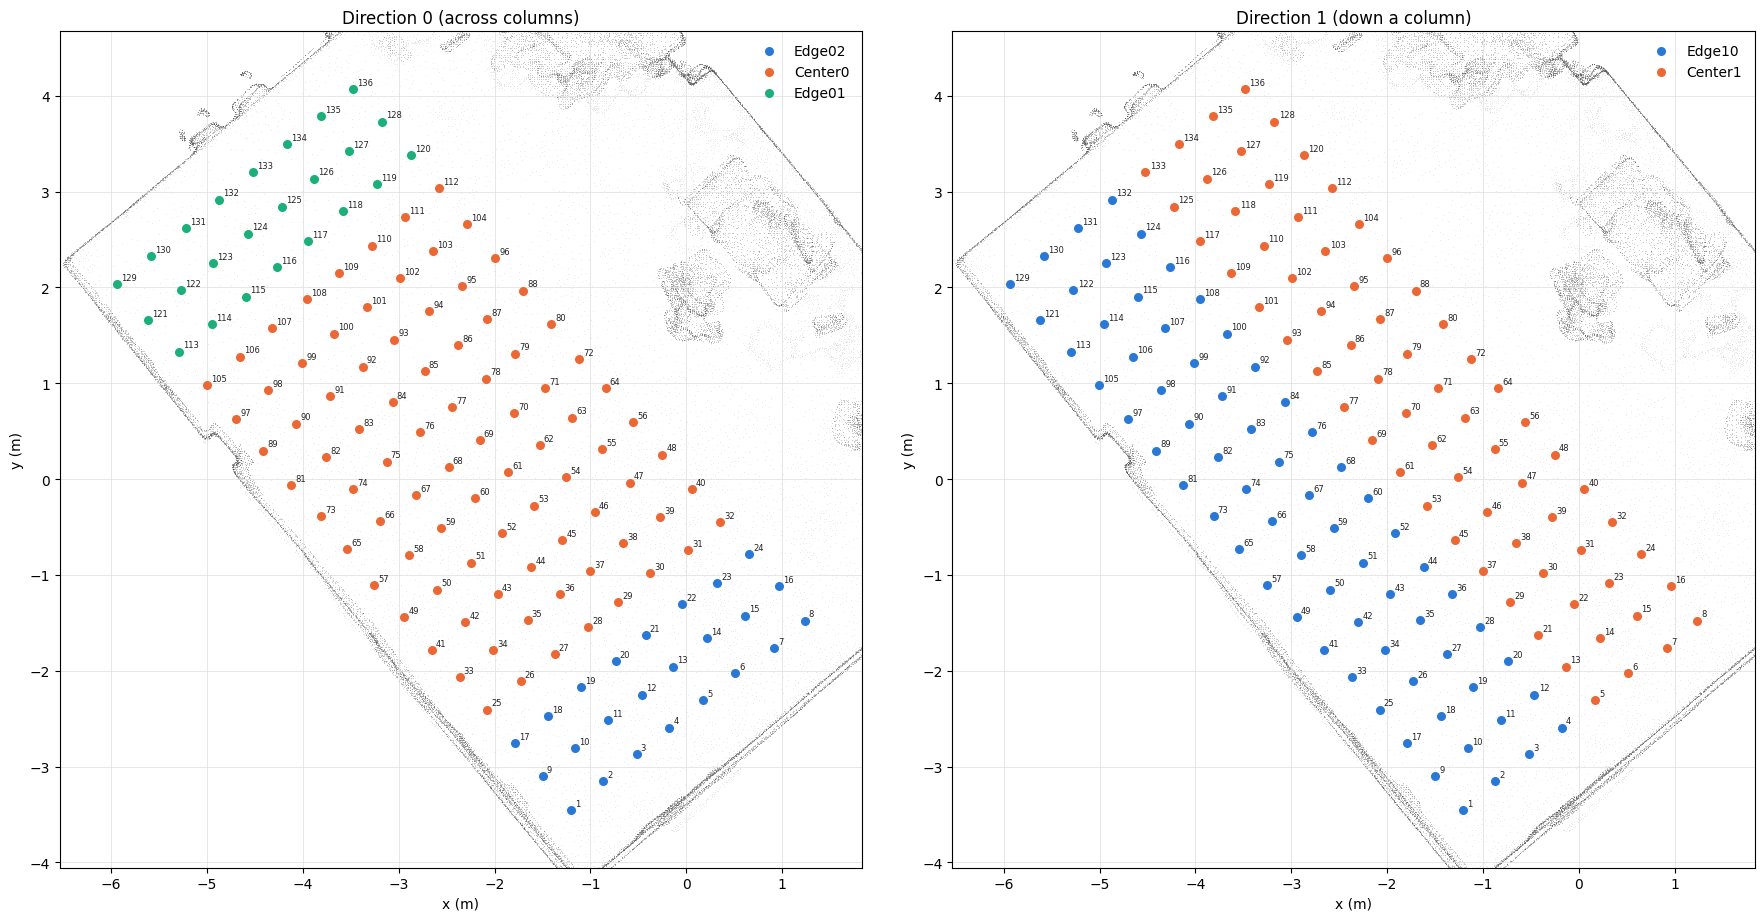

: 

: 

: 

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, col, regions, direction in [(axes[0], "dir0_region", DIR0_REGIONS, "Direction 0 (across columns)"),
                                    (axes[1], "dir1_region", DIR1_REGIONS, "Direction 1 (down a column)")]:
    draw_room(ax)
    for color, name in zip(REGION_COLORS, regions):
        m = markers[markers[col] == name]
        ax.scatter(m["x"], m["y"], s=30, color=color, zorder=3, label=name)
    for lab, r in markers.iterrows():
        ax.annotate(str(lab), (r.x, r.y), xytext=(3, 3), textcoords="offset points",
                    fontsize=6, color="#222222", zorder=4)
    pad = 0.6
    ax.set_xlim(markers["x"].min() - pad, markers["x"].max() + pad)
    ax.set_ylim(markers["y"].min() - pad, markers["y"].max() + pad)
    ax.grid(True, color="#dddddd", lw=0.5)
    ax.set_title(direction)
    ax.legend(loc="upper right", frameon=False)
fig.tight_layout()
plt.show()

## Tag locations per experiment

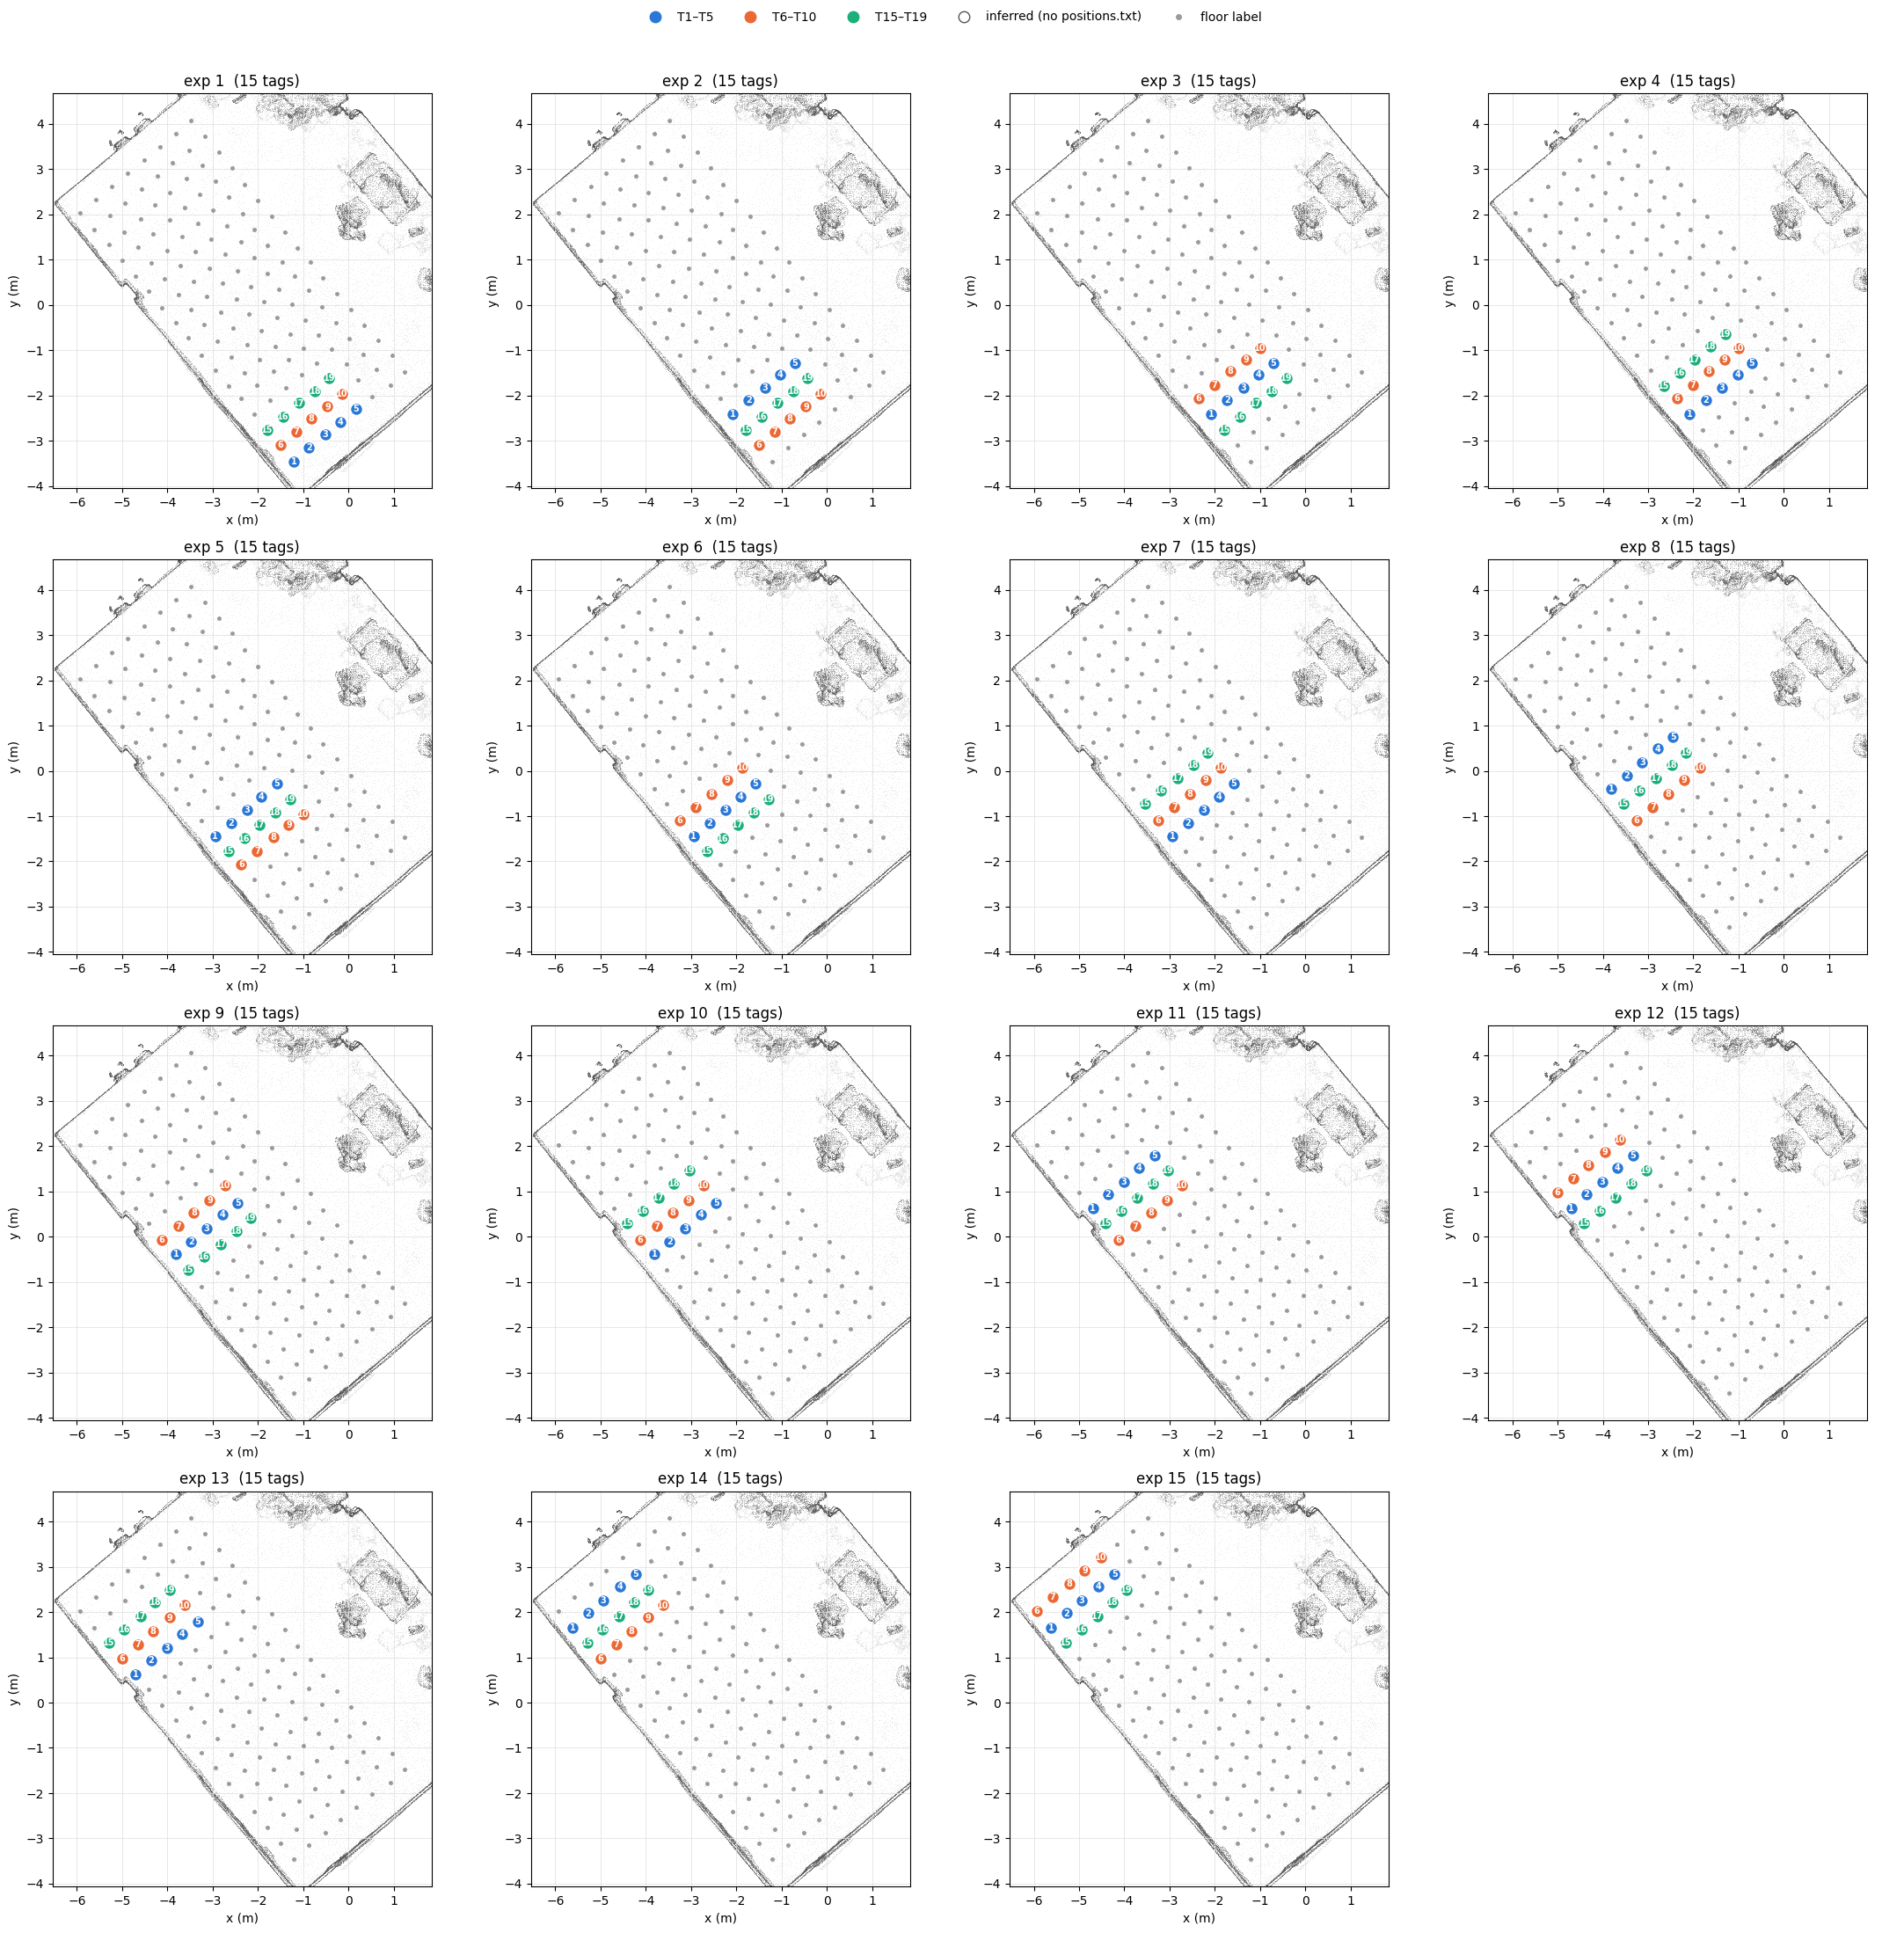

: 

: 

: 

In [ ]:
SHOW_MARKER_LABELS = False   # print every floor label (1–136) in grey
ZOOM = True                  # crop to the marker grid instead of the whole room
N_COLS = 4


def tag_color(tag):
    for color, tags in zip(GROUP_COLORS, TAG_GROUPS.values()):
        if int(tag) in tags:
            return color
    return "#333333"


def plot_experiment_positions(positions, n_cols=N_COLS, zoom=ZOOM, show_marker_labels=SHOW_MARKER_LABELS):
    """One panel per experiment folder. Inferred positions are drawn hollow; folders with no positions are left empty."""
    exps = list(positions)
    n_rows = int(np.ceil(len(exps) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 5.5 * n_rows), squeeze=False)

    for ax, name in zip(axes.flat, exps):
        pos = positions[name]
        draw_room(ax)
        if show_marker_labels:
            for lab, r in markers.iterrows():
                ax.annotate(str(lab), (r.x, r.y), fontsize=5, color="#9a9a9a",
                            xytext=(2, 2), textcoords="offset points")
        if pos is None:
            ax.set_title(f"exp {name}  (no positions.txt)", color="#9a9a9a")
        else:
            inferred = pos["source"].iloc[0] == "inferred"
            for tag, r in pos.iterrows():
                color = tag_color(tag)
                ax.scatter(r.x, r.y, s=110, color="white" if inferred else color,
                           edgecolors=color if inferred else "white", linewidths=1.5, zorder=3)
                ax.annotate(tag, (r.x, r.y), ha="center", va="center", fontsize=7,
                            color=color if inferred else "white", fontweight="bold", zorder=4)
            ax.set_title(f"exp {name}  ({len(pos)} tags{', inferred' if inferred else ''})")
        ax.grid(True, color="#dddddd", lw=0.5)
        if zoom:
            pad = 0.6
            ax.set_xlim(markers["x"].min() - pad, markers["x"].max() + pad)
            ax.set_ylim(markers["y"].min() - pad, markers["y"].max() + pad)

    for ax in axes.flat[len(exps):]:
        ax.axis("off")

    handles = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=9, label=g)
               for g, c in zip(TAG_GROUPS, GROUP_COLORS)]
    handles.append(plt.Line2D([], [], marker="o", ls="", color="white", markeredgecolor="#555555",
                              markersize=9, label="inferred (no positions.txt)"))
    handles.append(plt.Line2D([], [], marker="o", ls="", color="#9a9a9a", markersize=4, label="floor label"))
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    return fig


plot_experiment_positions(positions)
plt.show()

## Bidirectional phase and attenuation: `[exp][T1][T2][freq]`

Same as the metal-wall notebooks. For a pair `1 < 2` (by tag number), subscript `1` is the row with **Rx = T1** (Tx = T2) and `2` the row with **Rx = T2** (Tx = T1), matched per run:

$$\hat\alpha_{12} = \frac{1}{2}\left(\frac{\hat\beta_1}{\hat V_2} + \frac{\hat\beta_2}{\hat V_1}\right) \qquad
\hat\theta_{12} = \left(\frac{\hat\Theta_1 + \hat\Theta_2}{2}\right) \bmod \pi$$

- $\hat\Theta$ = `Unidirectional Phase (deg)` in radians → $\hat\theta_{12}$ (`theta_data`) in $[0, \pi)$
- $\hat\beta$ = `Unidirectional beta`, $\hat V$ = `Unidirectional V` → $\hat\alpha_{12}$ (`alpha_data`)

Only experiments with a CSV **and** positions are loaded. The `Channel_*_voltages` columns are skipped, since they make each file ~500 MB.

In [ ]:
def load_csv(exp_dir, with_voltages=False):
    f = next(Path(exp_dir).glob("*.csv"))
    cols = pd.read_csv(f, nrows=0).columns
    usecols = cols if with_voltages else [c for c in cols if "voltages" not in c.lower()]
    return pd.read_csv(f, usecols=usecols)


def tag_num(name):
    return int(str(name).replace("Tag", ""))


def bidirectional(df):
    """Join each Rx=a/Tx=b row with its Rx=b/Tx=a counterpart (a < b) and compute THETA, alpha."""
    keep = ["Rx", "Tx", "Frequency (MHz)", "Run Exp Num",
            "Unidirectional Phase (deg)", "Unidirectional V", "Unidirectional beta"]
    d = df[keep]
    fwd = d[d["Rx"].map(tag_num) < d["Tx"].map(tag_num)]    # Rx = a, Tx = b
    rev = d[d["Rx"].map(tag_num) > d["Tx"].map(tag_num)]    # Rx = b, Tx = a
    m = fwd.merge(rev, left_on=["Rx", "Tx", "Frequency (MHz)", "Run Exp Num"],
                  right_on=["Tx", "Rx", "Frequency (MHz)", "Run Exp Num"],
                  suffixes=("_a", "_b"), validate="one_to_one")
    th_a = np.deg2rad(m["Unidirectional Phase (deg)_a"])
    th_b = np.deg2rad(m["Unidirectional Phase (deg)_b"])
    m["THETA"] = ((th_a + th_b) / 2) % np.pi
    m["alpha"] = 0.5 * (m["Unidirectional beta_a"] / m["Unidirectional V_b"]
                        + m["Unidirectional beta_b"] / m["Unidirectional V_a"])
    return m.rename(columns={"Rx_a": "T1", "Tx_a": "T2"})


def to_nested(m, col):
    """-> {T1: {T2: {freq: array over runs}}} with tags in numeric order."""
    out = {}
    m = m.sort_values(["T1", "T2", "Frequency (MHz)", "Run Exp Num"],
                      key=lambda s: s.map(tag_num) if s.name in ("T1", "T2") else s)
    for (t1, t2, f), g in m.groupby(["T1", "T2", "Frequency (MHz)"], sort=False):
        out.setdefault(t1, {}).setdefault(t2, {})[int(f)] = g[col].to_numpy()
    return out


csv_exps = [d.name for d in exp_dirs if any(d.glob("*.csv")) and positions[d.name] is not None]
data = {name: load_csv(DATA_DIR / name) for name in csv_exps}
bidir = {name: bidirectional(df) for name, df in data.items()}
theta_data = {name: to_nested(m, "THETA") for name, m in bidir.items()}
alpha_data = {name: to_nested(m, "alpha") for name, m in bidir.items()}

for name, m in bidir.items():
    print(f"exp {name} (positions {positions[name]['source'].iloc[0]}): {len(m)} (pair, freq, run) rows, "
          f"{m.groupby(['T1', 'T2']).ngroups} pairs, {m['Frequency (MHz)'].nunique()} freqs")

exp 1 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 2 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 3 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 4 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 5 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 6 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 7 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 8 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 9 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 10 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 11 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 12 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 13 (positions file): 6930 (pair, freq, run) rows, 105 pairs, 22 freqs
exp 14 (positions file): 6930 (pair, freq, run)

: 

: 

: 

## Linear phase fit over frequency

`phase_linear_fit(exp, ta, tb)` takes one link (tag pair `Ta–Tb` in experiment `exp`), averages θ̂ over runs at every
frequency (circular mean, mod π), unwraps the means along frequency and fits a line θ̂(f) ≈ slope·f + intercept
(least squares).

- Top panel: runs (dots, moved onto the unwrapped branch), per-frequency mean and the fit line.
- Bottom panel: Δ = mean − fit at each frequency, with the ±standard-error band and a sine fit to Δ (`fit_sine`: A·sin(2π·f/P + φ) + c, best period P from a grid). The sine is only drawn, not returned.

Returns `(std_err, errors)`: `std_err` is the standard error of the fit, $\sqrt{\sum \Delta_k^2 / (n - 2)}$ (rad),
and `errors` is the list of Δ per frequency (rad). Frequency range: `FREQ_RANGE`.

In [ ]:
FREQ_RANGE = (800, 960)   # MHz, inclusive (min, max)


def circmean_mod_pi(x):
    return (np.angle(np.mean(np.exp(2j * np.asarray(x)))) / 2) % np.pi


def get_link(d, ta, tb):
    t1, t2 = sorted((ta, tb), key=tag_num)
    return d[t1][t2]


def fit_sine(x, y, n_periods=400, max_cond=100):
    """Least-squares y ≈ A·sin(2π·x/P + φ) + c. For each trial period P (2 grid steps … 2× the span) the fit is
    linear in (sin, cos, 1), so the best P is picked from a grid. Periods where the samples can't tell sin from cos
    (e.g. P = 20 MHz on a 10 MHz grid: every sample sits on a peak, cos ≈ 0) are skipped, since lstsq would give
    them a huge A. Returns (A, P, φ, c, function of x)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    best = None
    for P in np.linspace(2 * np.min(np.diff(x)), 2 * np.ptp(x), n_periods):
        w = 2 * np.pi * x / P
        M = np.column_stack([np.sin(w), np.cos(w), np.ones_like(x)])
        if np.linalg.cond(M) > max_cond:
            continue
        coef, *_ = np.linalg.lstsq(M, y, rcond=None)
        sse = np.sum((M @ coef - y) ** 2)
        if best is None or sse < best[0]:
            best = (sse, P, coef)
    _, P, (s, c_, c) = best
    A, phi = np.hypot(s, c_), np.arctan2(c_, s)
    return A, P, phi, c, lambda f: A * np.sin(2 * np.pi * np.asarray(f, float) / P + phi) + c


def phase_linear_fit(exp, ta, tb, freq_range=None, do_plot=True):
    """Linear fit of the unwrapped θ̂ of link Ta–Tb in experiment `exp` over frequency.

    exp       : experiment name, e.g. "6" or 6
    ta, tb    : tags, e.g. 3 or "Tag3"
    freq_range: (min, max) MHz, inclusive; None = FREQ_RANGE
    do_plot   : False = only compute (for looping over many links)
    Returns (standard error of the fit in rad, [Δ = mean − fit per frequency in rad]).
    """
    exp = str(exp)
    ta, tb = (t if str(t).startswith("Tag") else f"Tag{t}" for t in (ta, tb))
    freq_range = FREQ_RANGE if freq_range is None else freq_range
    fd = get_link(theta_data[exp], ta, tb)
    freqs = np.array([f for f in sorted(fd) if freq_range[0] <= f <= freq_range[1]])
    runs = [fd[f] for f in freqs]

    mean = np.unwrap([circmean_mod_pi(r) for r in runs], period=np.pi)
    runs = [r + np.pi * np.round((m - r) / np.pi) for r, m in zip(runs, mean)]   # same π branch as the mean
    slope, intercept = np.polyfit(freqs, mean, 1)
    fit = slope * freqs + intercept
    errors = mean - fit
    std_err = np.sqrt(np.sum(errors ** 2) / (len(freqs) - 2))

    if do_plot:
        labels = positions[exp]["label"]
        la, lb = (labels.get(str(tag_num(t)), "?") for t in (ta, tb))
        fig, (ax, ax_err) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
        ax.scatter(np.concatenate([np.full(len(r), f) for f, r in zip(freqs, runs)]), np.concatenate(runs),
                   s=8, color="#2a78d6", alpha=0.35, linewidths=0, label="runs")
        ax.plot(freqs, mean, color="#2a78d6", linewidth=2, marker="o", markersize=4, label="mean over runs")
        ax.plot(freqs, fit, color="#eb6834", linewidth=2, linestyle="--",
                label=f"fit: {slope * 1e3:.3f} mrad/MHz · f + {intercept:.2f} rad")
        ax.set_ylabel("θ̂ unwrapped (rad)")
        ax.set_title(f"θ̂ of {ta.replace('Tag', 'T')}–{tb.replace('Tag', 'T')} (labels {la}–{lb}), exp {exp}: "
                     f"linear fit over frequency", fontsize=11)
        ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

        ax_err.axhspan(-std_err, std_err, color="#eb6834", alpha=0.12, linewidth=0, label=f"±std err ({std_err:.3f} rad)")
        ax_err.axhline(0, color="#555555", linewidth=1)
        ax_err.plot(freqs, errors, color="#2a78d6", linewidth=1.5, marker="o", markersize=4, label="Δ = mean − fit")
        A, P, phi, c, sine = fit_sine(freqs, errors)
        f_dense = np.linspace(freqs[0], freqs[-1], 400)
        ax_err.plot(f_dense, sine(f_dense), color="#1baf7a", linewidth=2,
                    label=f"sine fit: A = {A:.3f} rad, period = {P:.1f} MHz")
        ax_err.set_ylabel("Δ (rad)")
        ax_err.set_xlabel("Frequency (MHz)")
        ax_err.set_xticks(freqs)
        ax_err.tick_params(axis="x", labelrotation=90, labelsize=8)
        ax_err.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
        for a in (ax, ax_err):
            a.grid(color="#d9d9d9", linewidth=0.8)
            a.set_axisbelow(True)
            for side in ("top", "right"):
                a.spines[side].set_visible(False)
        fig.tight_layout()
        plt.show()

    return std_err, errors.tolist()

: 

: 

: 

### Try a few links

`TEST_LINKS` = `[(exp, Ta, Tb), ...]`, plotted one by one.

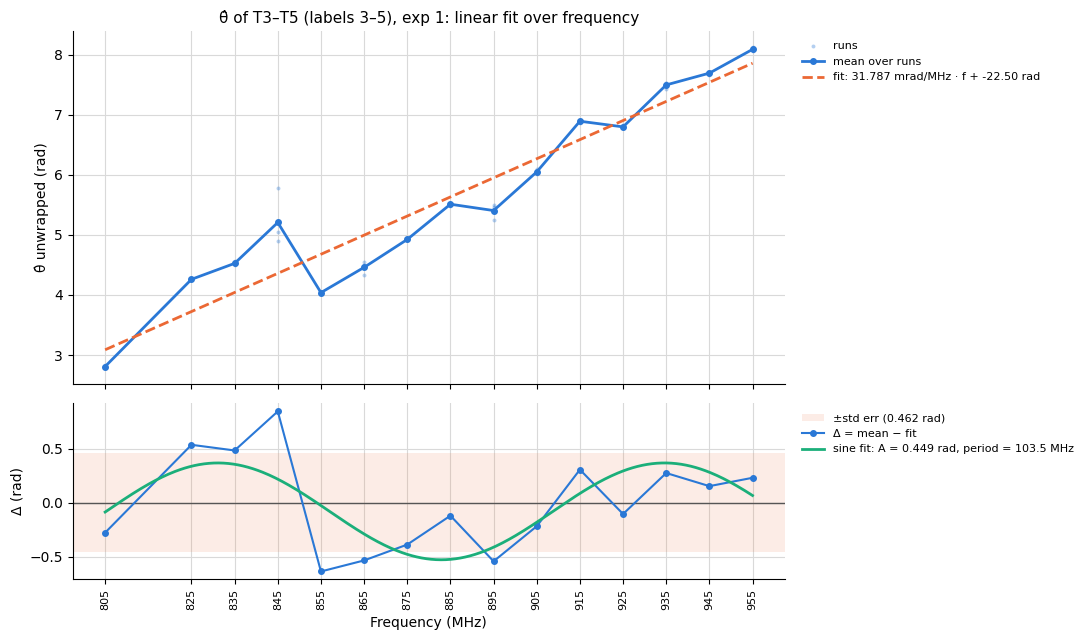

exp 1, T3–T5: std err = 0.4623 rad, Δ = [-0.278  0.537  0.484  0.847 -0.638 -0.536 -0.389 -0.121 -0.544 -0.219
  0.306 -0.106  0.275  0.153  0.231]


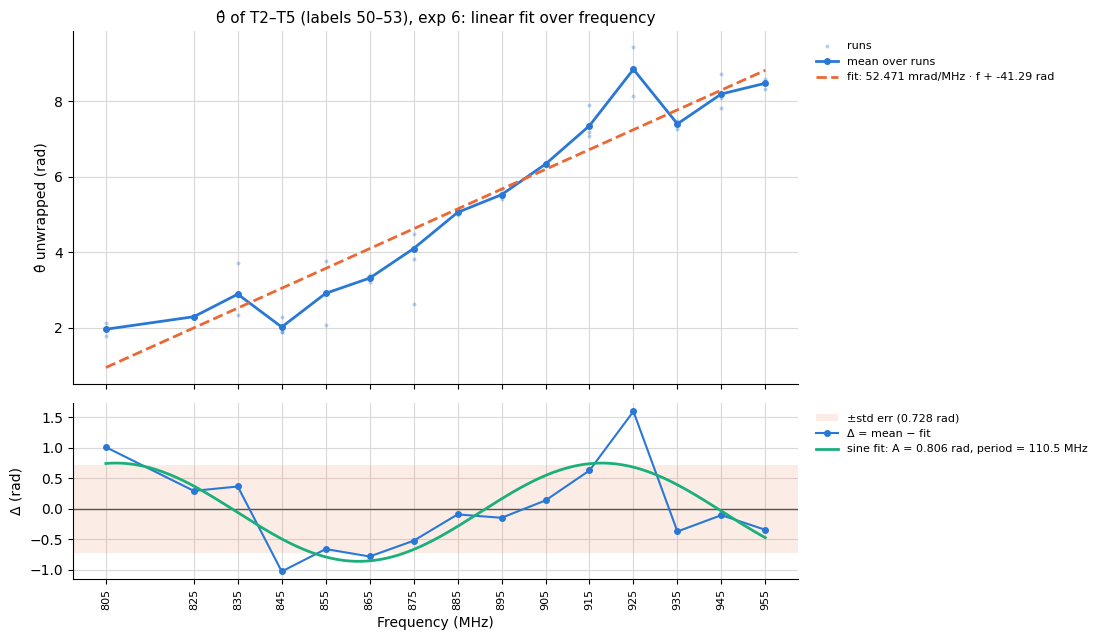

exp 6, T2–T5: std err = 0.7284 rad, Δ = [ 1.013  0.296  0.367 -1.027 -0.659 -0.781 -0.523 -0.091 -0.146  0.139
  0.631  1.6   -0.371 -0.103 -0.344]


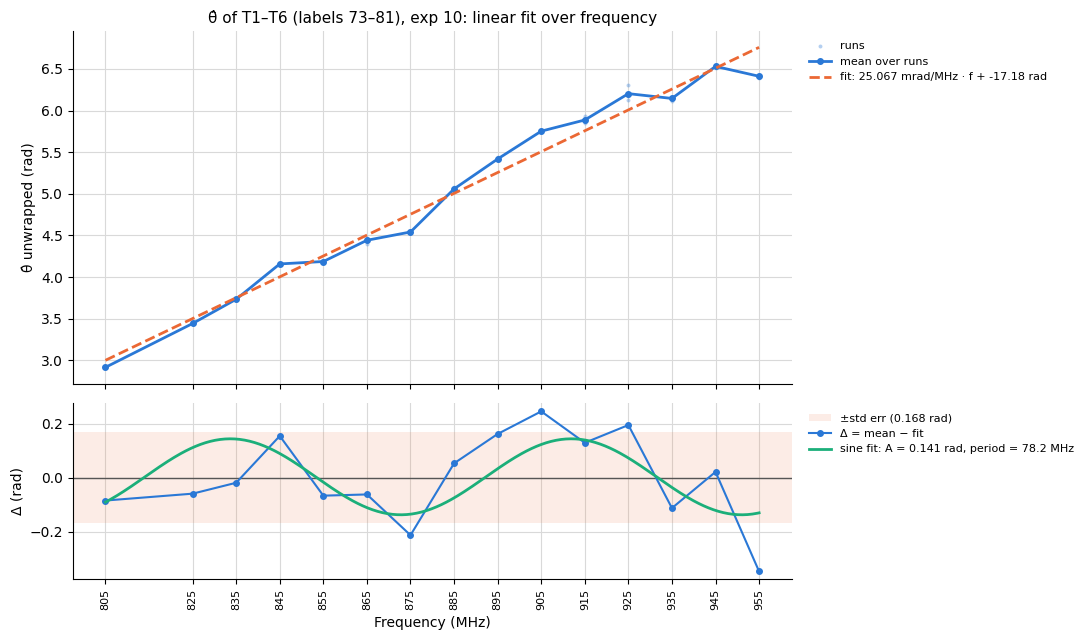

exp 10, T1–T6: std err = 0.1682 rad, Δ = [-0.085 -0.059 -0.019  0.155 -0.067 -0.062 -0.213  0.053  0.163  0.246
  0.13   0.196 -0.113  0.022 -0.348]


: 

: 

: 

In [ ]:
TEST_LINKS = [("1", 3, 5), ("6", 2, 5), ("10", 1, 6)]

for exp, ta, tb in TEST_LINKS:
    std_err, errors = phase_linear_fit(exp, ta, tb)
    print(f"exp {exp}, T{ta}–T{tb}: std err = {std_err:.4f} rad, Δ = {np.round(errors, 3)}")

### All links (no plots)

Every tag pair in every experiment with `do_plot=False`. `fit_results` has one row per link: experiment, tags, floor labels, standard error and the list of Δ per frequency.

In [ ]:
rows = []
for exp, by_t1 in theta_data.items():
    labels = positions[exp]["label"]
    for t1, by_t2 in by_t1.items():
        for t2 in by_t2:
            std_err, errors = phase_linear_fit(exp, t1, t2, do_plot=False)
            rows.append({"exp": exp, "T1": t1, "T2": t2,
                         "label1": labels.get(str(tag_num(t1))), "label2": labels.get(str(tag_num(t2))),
                         "std_err": std_err, "errors": errors})
fit_results = pd.DataFrame(rows)
print(f"{len(fit_results)} links")
print(fit_results["std_err"].describe().to_string())

1575 links
count    1575.000000
mean        0.452942
std         0.270217
min         0.090380
25%         0.263675
50%         0.386676
75%         0.559308
max         1.677382


: 

: 

: 

### Save the fits

One file per experiment, `roomsweeps_data/<exp>/fits/phase_fit.csv`, one row per link (`T1 < T2`): tags, floor labels, `std_err` (rad), the sine fit to Δ (`sine_A` in rad, `sine_period_mhz`) and Δ per frequency (`delta_<MHz>`, rad, frequencies in `FREQ_RANGE`). Read by `roomsweeps_wall_distance_fit.py`. It is in a subfolder so `load_csv`'s `*.csv` glob still finds only the measurement CSV.

In [ ]:
FIT_FILE = Path("fits") / "phase_fit.csv"   # in roomsweeps_data/<exp>/; not next to the measurement CSV (load_csv globs *.csv)

for exp, g in fit_results.groupby("exp", sort=False):
    rows = []
    for r in g.itertuples():
        fd = get_link(theta_data[exp], r.T1, r.T2)
        freqs = [f for f in sorted(fd) if FREQ_RANGE[0] <= f <= FREQ_RANGE[1]]
        A, P, *_ = fit_sine(freqs, r.errors)
        rows.append({"T1": tag_num(r.T1), "T2": tag_num(r.T2), "label1": r.label1, "label2": r.label2,
                     "std_err": r.std_err, "sine_A": A, "sine_period_mhz": P,
                     **{f"delta_{f}": e for f, e in zip(freqs, r.errors)}})
    path = DATA_DIR / exp / FIT_FILE
    path.parent.mkdir(exist_ok=True)
    pd.DataFrame(rows).to_csv(path, index=False)
    print(f"wrote {path.relative_to(ROOT)} ({len(rows)} links)")

: 

: 

: 